In [1]:
%load_ext autoreload
%autoreload 2

# Load Hardware Data

# Device selection

In [2]:
from cobos.tokens import ibm_token_us, us_instance_token_basq, us_instance_token_previous
from qiskit_ibm_runtime import QiskitRuntimeService

channel = "ibm_cloud"
# device = "ibm_fez"
# device = "ibm_sherbrooke"
# device = "ibm_torino"
device = "ibm_marrakesh"
# device = "ibm_aachen"
# device = "ibm_kingston"

service = QiskitRuntimeService(channel=channel, token=ibm_token_us, instance=us_instance_token_basq)
backend = service.backend("ibm_kingston")

qiskit_runtime_service._discover_account:WARNING:2026-05-21 09:43:51,711: Loading account with the given token. A saved account will not be used.


# Auxiliary lattice plot

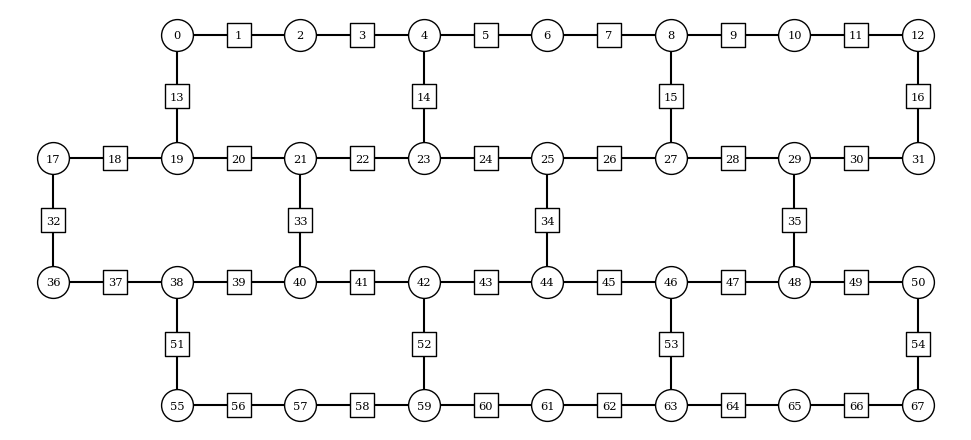

In [3]:
from z2hex.geometry import HeavyHexLattice

plaquette_width = 3
plaquette_height = 3

lattice = HeavyHexLattice(plaquette_width, plaquette_height)
# nlayouts = len(lattice.get_all_layouts(backend))
# print(f"{nlayouts} possible layouts")
lattice.plot_lattice(number_qubits=True)

# Simulation settings

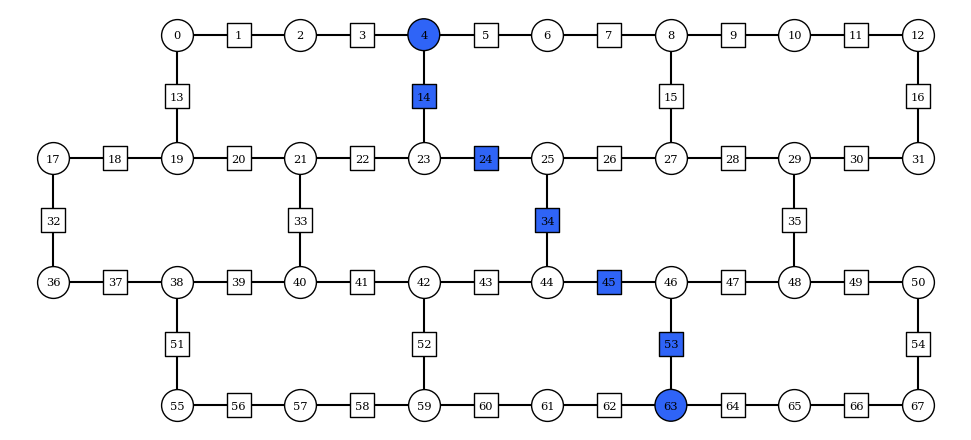

In [4]:
from z2hex.gdd import zero_mean
from utils.hexec import create_estimator_options
from utils.execrecord import ExecutionRecord
from utils.hexec import ExecDB
from functools import partial

lattice_dims = (plaquette_width, plaquette_height)
J = 5
h = 2
lamb = 1

x_basis = False

fractional_gates = False

# string = [27, 26, 34, 43, 52, 60, 59]
# string = [4, 10, 17, 24, 30]
string = [4, 14, 24, 34, 45, 53, 63]
# string = [1, 2, 9, 15, 19, 16, 17, 21, 22, 24, 26, 27, 29]

final_time = 4.5
dt = 0.125
steps = 36
desired_error = 1e-2

confidence = 0.7

odr = True
postselect_odr = True
flip_threshold = 1
all_or_first_layout_qubit = None
forbidden_qubits = []
max_layouts = 5
recovery = True
# g_func = None
# g_func = partial(counteract_rotation, ham_param=J)
# g_func = partial(constant, angle=np.pi)
# g_func = random
g_func = zero_mean

pt_num_randomizations = 50
pt_shots_per_randomization = 2000

shots = pt_num_randomizations * pt_shots_per_randomization
max_shots = 100000
shots = 480000
# shots = 75000
# max_shots = 75000

final_twirl_randomizations = pt_num_randomizations
if shots > max_shots:
    final_twirl_randomizations = int(final_twirl_randomizations * max_shots / shots)
if all_or_first_layout_qubit == True:
    final_twirl_randomizations = int(final_twirl_randomizations/max_layouts)
if final_twirl_randomizations < 1:
    final_twirl_randomizations = 1

sampler_options = {
    "default_shots": shots,
    "execution": {
        "init_qubits": True,
        "meas_type": "classified"
    },
    "dynamical_decoupling": {
        "enable": False,
        "sequence_type": "XY4"
    },
    "twirling": {
        "enable_gates": True,
        "enable_measure": True,
        "num_randomizations": final_twirl_randomizations,
        "shots_per_randomization": pt_shots_per_randomization
    }
}
# execution_database = "z2_hex_jobs_dec.json" # Last db with good jobs / Not in the new order
execution_database = "z2_hex_jobs_select.json"
jobs_result_folder = execution_database.split(".")[0] + "/"
job_db = ExecDB(execution_database)

circ_folder_path = "Circuits/"

execution_record_path = "../../../../Executions_record.xlsx"
execrecord = ExecutionRecord(execution_record_path)

curated_data_folder_path = "Curated data/"

lattice.plot_highlighted_qubits(string, colors=["#2f64f7"]*len(string), number_qubits=True, filepath="z2hex_quench_initial_state.png")

# Load jobs

In [5]:
from utils.postselection_multithreaded import load_postselected_jobs_obs
import pickle
import os

curated_data_filepath = os.path.join(curated_data_folder_path, f"z2hexquench_curated_data_{device}_px_{lattice_dims[0]}_py_{lattice_dims[1]}_maxt_{final_time}_dt_{dt}_steps_{steps}_J_{J:.04f}_h_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else g_func}_shots_{shots}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string[:10]])}_xbasis_{x_basis}_dd_{sampler_options["dynamical_decoupling"]["enable"]}_pt_{sampler_options["twirling"]["enable_gates"]}_ft_{flip_threshold}_pODR_{postselect_odr}_confidence_{confidence}.pkl")

with open(curated_data_filepath, "rb") as f:
    hardware_observables, hardware_observables_confidence, samples_dicts, postselected_samples_dicts, layouts = pickle.load(f)

In [6]:
import os

os.path.abspath(curated_data_filepath)

'/Users/cobos/MEGA/Doctorado/2nd year/IBM hardware execution/Repo/src/notebooks/Z2/Curated data/z2hexquench_curated_data_ibm_marrakesh_px_3_py_3_maxt_4.5_dt_0.125_steps_36_J_5.0000_h_2.0000_lamb_1.0000_g_zero_mean_shots_480000_fqb_None_string_4-14-24-34-45-53-63_xbasis_False_dd_False_pt_True_ft_1_pODR_True_confidence_0.7.pkl'

# Load TN data

In [8]:
import numpy as np
import os

tn_dt = 0.01
tn_final_time = 8
tn_exp_order = "_order30" #"_adaptive"
tn_bond_dimension = 128
tn_data_folderpath = "TN Data/"
tn_data_limit = int(final_time / tn_dt)
tn_data_step = int(dt / tn_dt)
stringname = "3string"

# tn_data_filepath = os.path.join(tn_data_folderpath, f"converted_data_BUG_g{h:.02f}_m{J:.02f}_ROWS{plaquette_width}_COLS{plaquette_height}_dt{tn_dt:.03f}_Tmax{tn_final_time:.02f}_exp_order{tn_exp_order}_M{tn_bond_dimension:05d}.txt")
# tn_data_obs_filepath = os.path.join(tn_data_folderpath, f"converted_data_{stringname}_BUG_g{h:.02f}_m{J:.02f}_{plaquette_width}x{plaquette_height}_dt{tn_dt:.03f}_Tmax{tn_final_time:.02f}_exp_order{tn_exp_order}_M{tn_bond_dimension:05d}.txt")
# tn_data_obs_filepath = os.path.join(tn_data_folderpath, f"converted_data_{stringname}_BUG_g{h:.02f}_m{J:.02f}_{plaquette_width}x{plaquette_height}_dt{tn_dt:.03f}_Tmax{tn_final_time:.02f}_exp{tn_exp_order}_M{tn_bond_dimension:05d}.txt")
tn_data_obs_filepath = os.path.join(tn_data_folderpath, "IBM_1string_BUG_g2.00_m5.00_ROWS3_COLS3_dt0.010_Tmax6.00_M00128.txt")
# tn_data_probs_filepath = os.path.join(tn_data_folderpath, f"Probs4_mass_{plaquette_width}x{plaquette_height}_m_{J}_g_{h}.out")
tn_observables = np.loadtxt(tn_data_obs_filepath)
# tn_probs = np.loadtxt(tn_data_probs_filepath)[:, 2:]

In [9]:
tn_data_obs_filepath

'TN Data/converted_data_3string_BUG_g2.00_m5.00_2x2_dt0.010_Tmax8.00_exp_order30_M00128.txt'

In [10]:
tn_data_probs_filepath

'TN Data/Probs4_mass_2x2_m_5_g_2.out'

# Plots

## 2x2

### 1 string

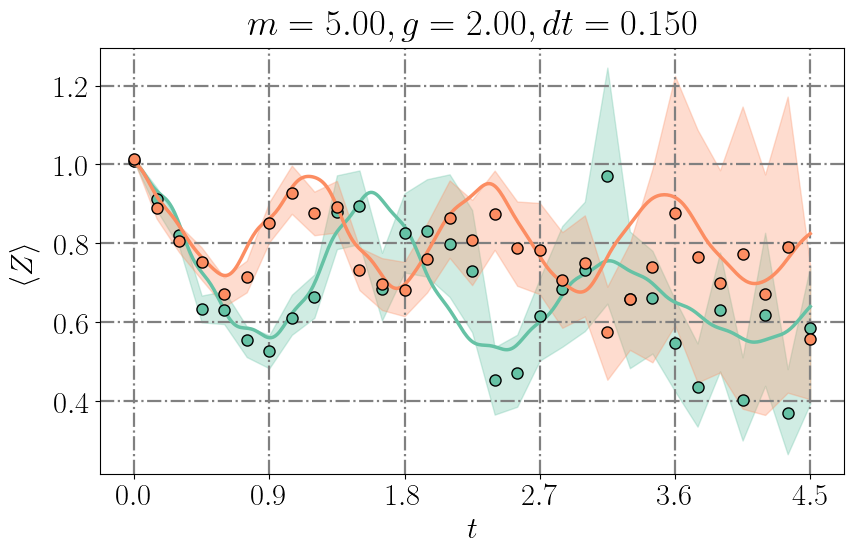

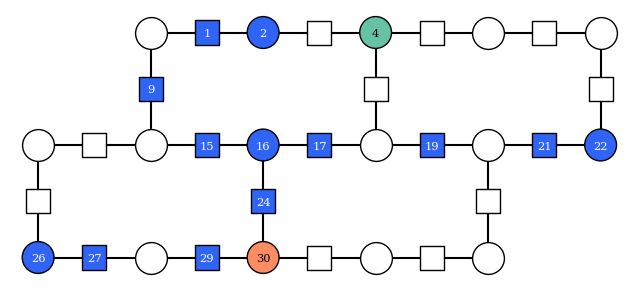

In [13]:
from utils.plotting import plot_individual_qubits_htn_comparison
import matplotlib.pyplot as plt
import numpy as np

qubits = [4, 30]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}, dt = {dt:.03f}$"
legend = False
x_ticks = np.linspace(0, final_time, 6)
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"
y_lim = None # "data" for data limits, None for auto, [,] for custom

plot_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = hardware_observables[0].copy()
hardware_observables_confidence_to_plot = hardware_observables_confidence[0]
tn_observables_to_plot = tn_observables[:tn_data_limit, :]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_htn_comparison(hardware_observables_to_plot, tn_observables_to_plot, qubits, observable_confidence_hardware=hardware_observables_confidence_to_plot, x_ticks=x_ticks, x_label=x_label, title=title, y_label=y_label, y_lim=y_lim, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

In [ ]:
tn_observables_to_plot

In [ ]:
from utils.plotting import plot_individual_qubits_htn_comparison
import matplotlib.pyplot as plt

qubits = [14, 20]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}, dt = {dt:.03f}$"
legend = False
x_ticks = np.linspace(0, final_time, 6)
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"
y_lim = "data" # "data" for data limits, None for auto, [,] for custom

plot_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = hardware_observables[0]
hardware_observables_confidence_to_plot = hardware_observables_confidence[0]
tn_observables_to_plot = tn_observables[:tn_data_limit, :]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_htn_comparison(hardware_observables_to_plot, tn_observables_to_plot, qubits, observable_confidence_hardware=hardware_observables_confidence_to_plot, x_ticks=x_ticks, x_label=x_label, title=title, y_label=y_label, y_lim=y_lim, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

In [ ]:
from utils.plotting import plot_individual_qubits_htn_comparison
import matplotlib.pyplot as plt

qubits = [16, 18]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}, dt = {dt:.03f}$"
legend = False
x_ticks = np.linspace(0, final_time, 6)
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"
y_lim = "data" # "data" for data limits, None for auto, [,] for custom

plot_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = hardware_observables[0]
hardware_observables_confidence_to_plot = hardware_observables_confidence[0]
tn_observables_to_plot = tn_observables[:tn_data_limit, :]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_htn_comparison(hardware_observables_to_plot, tn_observables_to_plot, qubits, observable_confidence_hardware=hardware_observables_confidence_to_plot, x_ticks=x_ticks, x_label=x_label, title=title, y_label=y_label, y_lim=y_lim, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

In [ ]:
from utils.plotting import plot_individual_qubits_htn_comparison
import matplotlib.pyplot as plt

qubits = [15, 19]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}, dt = {dt:.03f}$"
legend = False
x_ticks = np.linspace(0, final_time, 6)
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"
y_lim = "data" # "data" for data limits, None for auto, [,] for custom

plot_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = hardware_observables[0]
hardware_observables_confidence_to_plot = hardware_observables_confidence[0]
tn_observables_to_plot = tn_observables[:tn_data_limit, :]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_htn_comparison(hardware_observables_to_plot, tn_observables_to_plot, qubits, observable_confidence_hardware=hardware_observables_confidence_to_plot, x_ticks=x_ticks, x_label=x_label, title=title, y_label=y_label, y_lim=y_lim, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

In [ ]:
from utils.plotting import plot_individual_qubits_htn_comparison
import matplotlib.pyplot as plt

qubits = [10, 17, 24]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}, dt = {dt:.03f}$"
legend = False
x_ticks = np.linspace(0, final_time, 6)
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"
y_lim = "data" # "data" for data limits, None for auto, [,] for custom

plot_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = hardware_observables[0]
hardware_observables_confidence_to_plot = hardware_observables_confidence[0]
tn_observables_to_plot = tn_observables[:tn_data_limit, :]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_htn_comparison(hardware_observables_to_plot, tn_observables_to_plot, qubits, observable_confidence_hardware=hardware_observables_confidence_to_plot, x_ticks=x_ticks, x_label=x_label, title=title, y_label=y_label, y_lim=y_lim, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

### 3 string

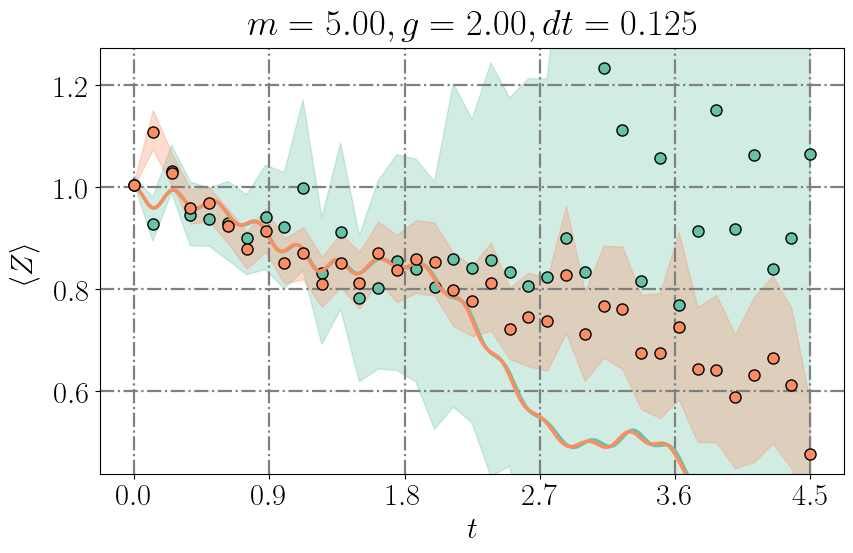

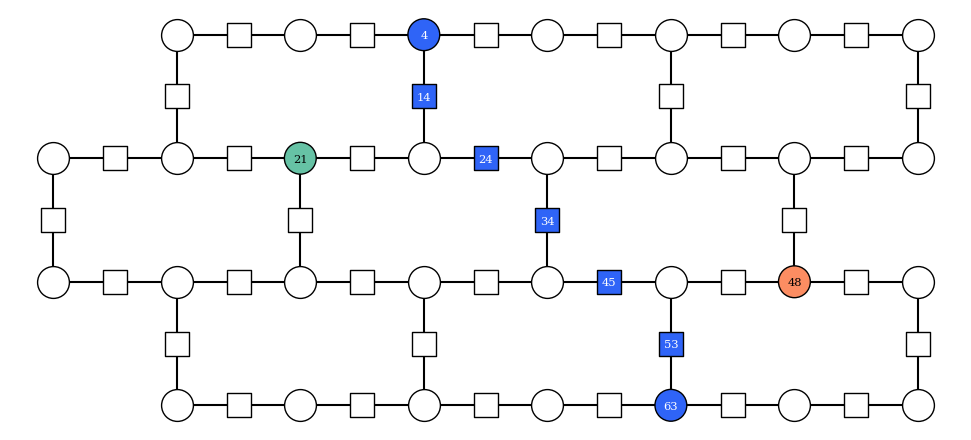

In [12]:
from utils.plotting import plot_individual_qubits_htn_comparison
import matplotlib.pyplot as plt

qubits = [21, 48]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}, dt = {dt:.03f}$"
legend = False
x_ticks = np.linspace(0, final_time, 6)
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"
y_lim = "data" # "data" for data limits, None for auto, [,] for custom

plot_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = hardware_observables[0].copy()
hardware_observables_confidence_to_plot = hardware_observables_confidence[0]
tn_observables_to_plot = tn_observables[:tn_data_limit, :]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_htn_comparison(hardware_observables_to_plot, tn_observables_to_plot, qubits, observable_confidence_hardware=hardware_observables_confidence_to_plot, x_ticks=x_ticks, x_label=x_label, title=title, y_label=y_label, y_lim=y_lim, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

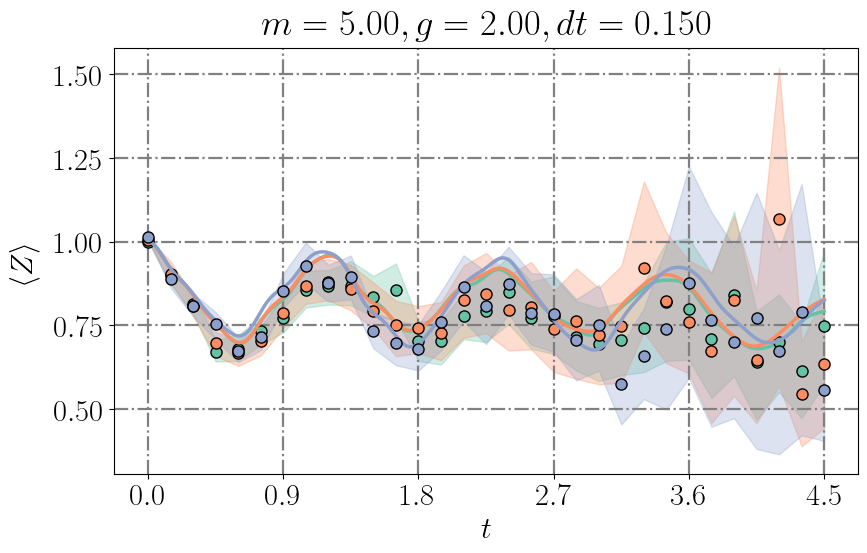

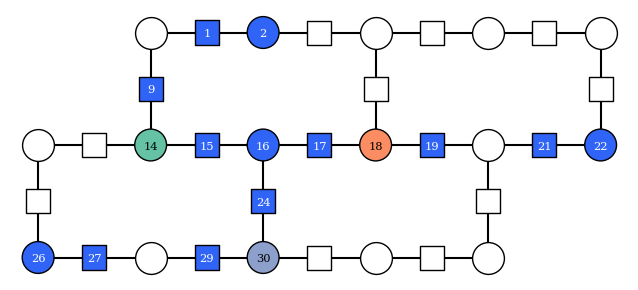

In [16]:
from utils.plotting import plot_individual_qubits_htn_comparison
import matplotlib.pyplot as plt

qubits = [14, 18, 30]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}, dt = {dt:.03f}$"
legend = False
x_ticks = np.linspace(0, final_time, 6)
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"
y_lim = None # "data" for data limits, None for auto, [,] for custom

plot_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = hardware_observables[0]
hardware_observables_confidence_to_plot = hardware_observables_confidence[0]
tn_observables_to_plot = tn_observables[:tn_data_limit, :]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_htn_comparison(hardware_observables_to_plot, tn_observables_to_plot, qubits, observable_confidence_hardware=hardware_observables_confidence_to_plot, x_ticks=x_ticks, x_label=x_label, title=title, y_label=y_label, y_lim=y_lim, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

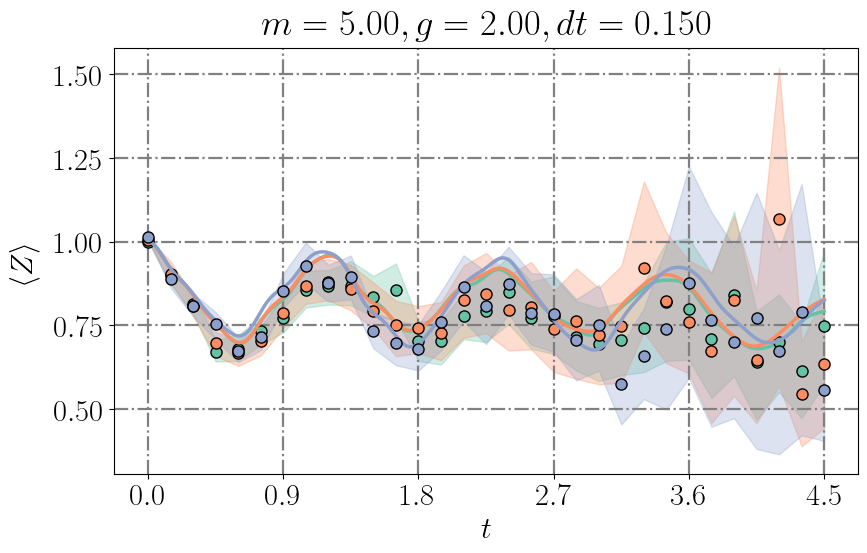

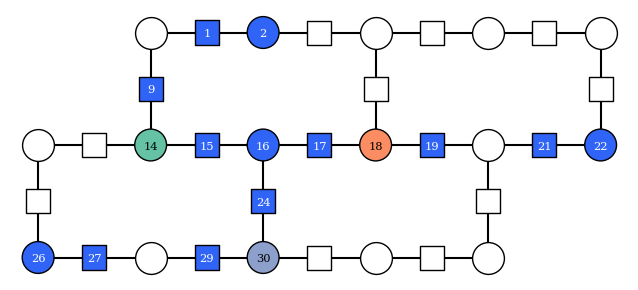

In [ ]:
from utils.plotting import plot_individual_qubits_htn_comparison
import matplotlib.pyplot as plt

qubits = [14, 18, 30]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}, dt = {dt:.03f}$"
legend = False
x_ticks = np.linspace(0, final_time, 6)
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"
y_lim = None # "data" for data limits, None for auto, [,] for custom

plot_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = hardware_observables[0]
hardware_observables_confidence_to_plot = hardware_observables_confidence[0]
tn_observables_to_plot = tn_observables[:tn_data_limit, :]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_htn_comparison(hardware_observables_to_plot, tn_observables_to_plot, qubits, observable_confidence_hardware=hardware_observables_confidence_to_plot, x_ticks=x_ticks, x_label=x_label, title=title, y_label=y_label, y_lim=y_lim, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

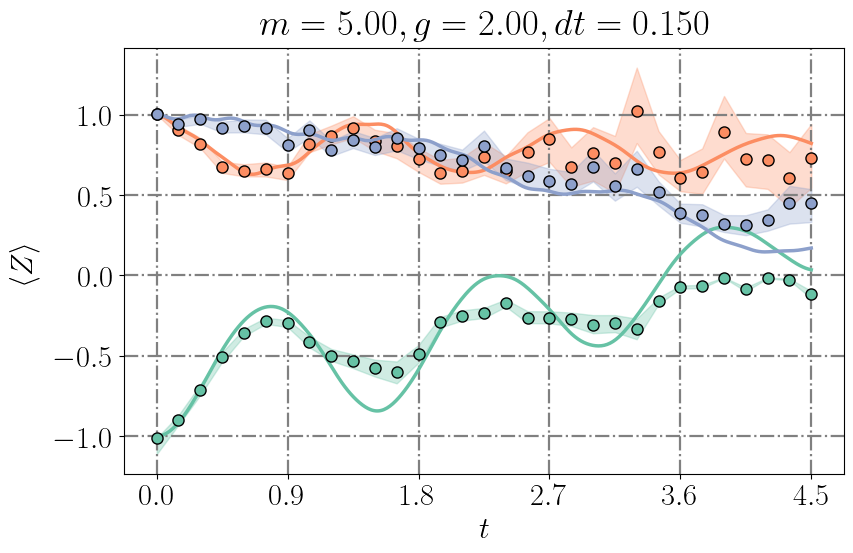

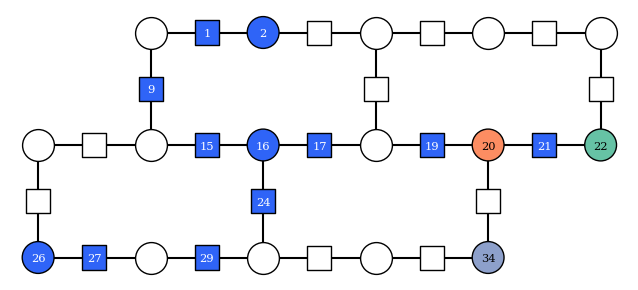

In [17]:
from utils.plotting import plot_individual_qubits_htn_comparison
import matplotlib.pyplot as plt

qubits = [22, 20, 34]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}, dt = {dt:.03f}$"
legend = False
x_ticks = np.linspace(0, final_time, 6)
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"
y_lim = None # "data" for data limits, None for auto, [,] for custom

plot_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = hardware_observables[0]
hardware_observables_confidence_to_plot = hardware_observables_confidence[0]
tn_observables_to_plot = tn_observables[:tn_data_limit, :]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_htn_comparison(hardware_observables_to_plot, tn_observables_to_plot, qubits, observable_confidence_hardware=hardware_observables_confidence_to_plot, x_ticks=x_ticks, x_label=x_label, title=title, y_label=y_label, y_lim=y_lim, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

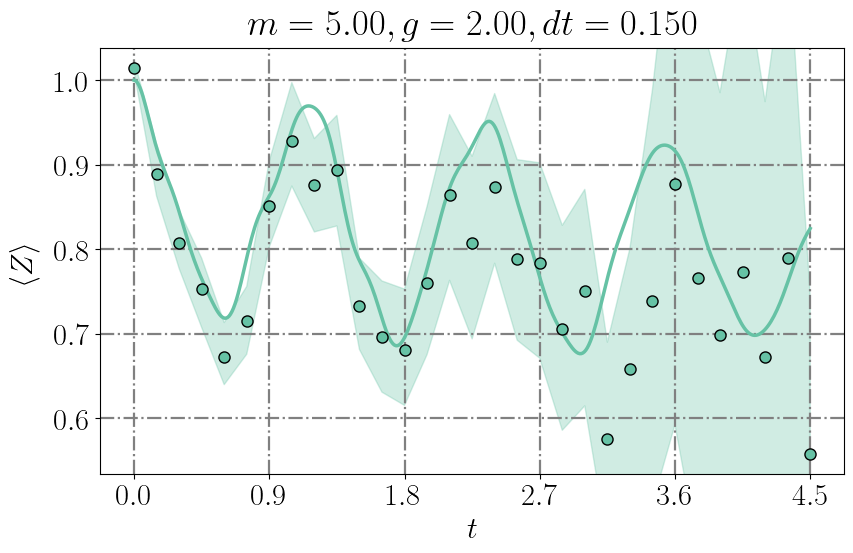

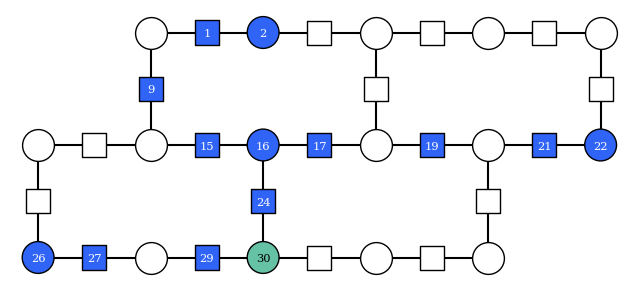

In [18]:
from utils.plotting import plot_individual_qubits_htn_comparison
import matplotlib.pyplot as plt

qubits = [30]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}, dt = {dt:.03f}$"
legend = False
x_ticks = np.linspace(0, final_time, 6)
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"
y_lim = "data" # "data" for data limits, None for auto, [,] for custom

plot_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = hardware_observables[0]
hardware_observables_confidence_to_plot = hardware_observables_confidence[0]
tn_observables_to_plot = tn_observables[:tn_data_limit, :]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_htn_comparison(hardware_observables_to_plot, tn_observables_to_plot, qubits, observable_confidence_hardware=hardware_observables_confidence_to_plot, x_ticks=x_ticks, x_label=x_label, title=title, y_label=y_label, y_lim=y_lim, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

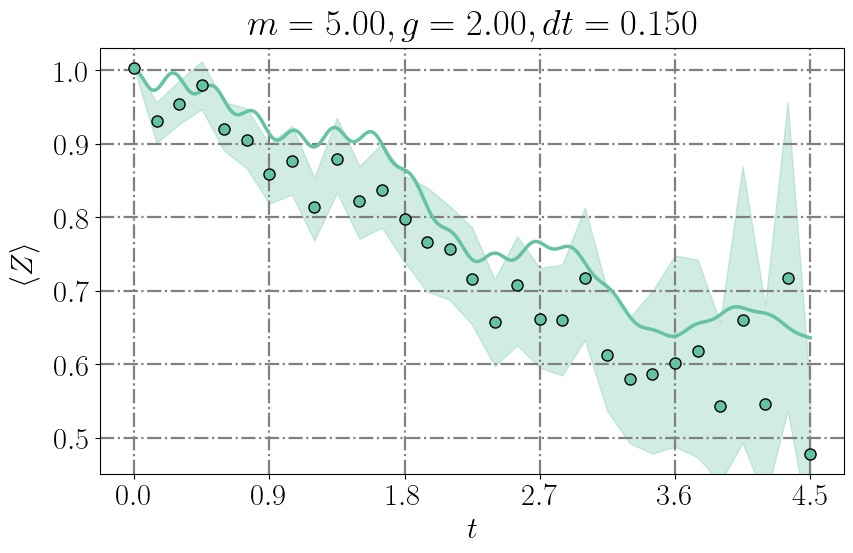

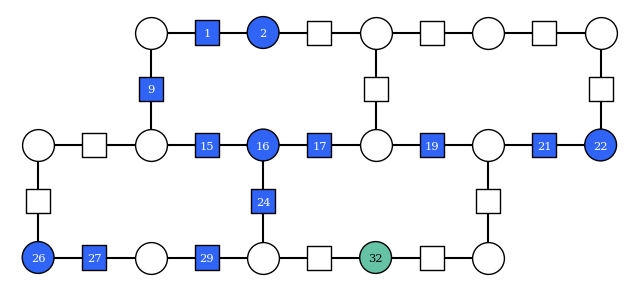

In [19]:
from utils.plotting import plot_individual_qubits_htn_comparison
import matplotlib.pyplot as plt

qubits = [32]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}, dt = {dt:.03f}$"
legend = False
x_ticks = np.linspace(0, final_time, 6)
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"
y_lim = "data" # "data" for data limits, None for auto, [,] for custom

plot_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = hardware_observables[0]
hardware_observables_confidence_to_plot = hardware_observables_confidence[0]
tn_observables_to_plot = tn_observables[:tn_data_limit, :]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_htn_comparison(hardware_observables_to_plot, tn_observables_to_plot, qubits, observable_confidence_hardware=hardware_observables_confidence_to_plot, x_ticks=x_ticks, x_label=x_label, title=title, y_label=y_label, y_lim=y_lim, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

In [ ]:
from utils.plotting import plot_individual_qubits_htn_comparison
import matplotlib.pyplot as plt

qubits = [2, 22, 26, 32]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}, dt = {dt:.03f}$"
legend = False
x_ticks = np.linspace(0, final_time, 6)
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"
y_lim = "data" # "data" for data limits, None for auto, [,] for custom

plot_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = hardware_observables[0]
hardware_observables_confidence_to_plot = hardware_observables_confidence[0]
tn_observables_to_plot = tn_observables[:tn_data_limit, :]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_htn_comparison(hardware_observables_to_plot, tn_observables_to_plot, qubits, observable_confidence_hardware=hardware_observables_confidence_to_plot, x_ticks=x_ticks, x_label=x_label, title=title, y_label=y_label, y_lim=y_lim, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

In [ ]:
from utils.plotting import plot_individual_qubits_htn_comparison
import matplotlib.pyplot as plt

qubits = [2, 16, 22, 26]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}, dt = {dt:.03f}$"
legend = False
x_ticks = np.linspace(0, final_time, 6)
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"
y_lim = "data" # "data" for data limits, None for auto, [,] for custom

plot_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = hardware_observables[0]
hardware_observables_confidence_to_plot = hardware_observables_confidence[0]
tn_observables_to_plot = tn_observables[:tn_data_limit, :]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_htn_comparison(hardware_observables_to_plot, tn_observables_to_plot, qubits, observable_confidence_hardware=hardware_observables_confidence_to_plot, x_ticks=x_ticks, x_label=x_label, title=title, y_label=y_label, y_lim=y_lim, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

## Occupation correlators

AttributeError: 'list' object has no attribute 'get_label'

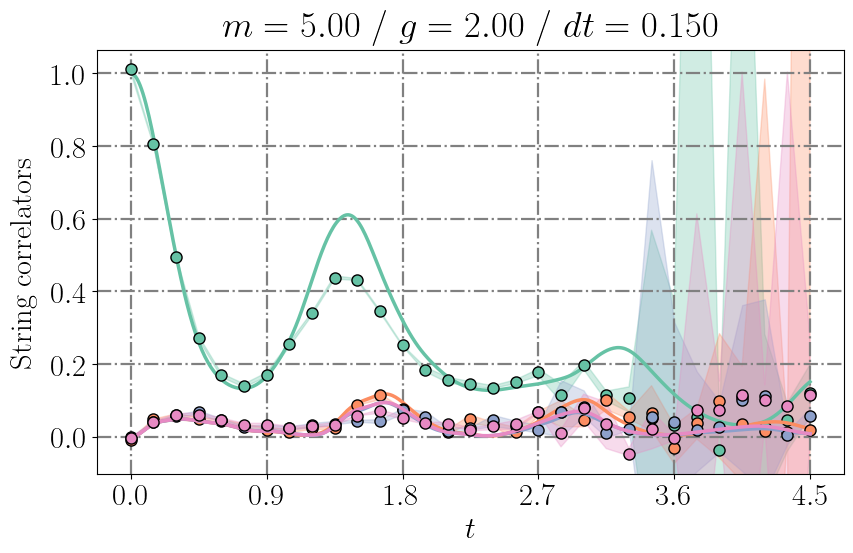

In [20]:
from utils.plotting import plot_individual_qubits_htn_comparison
from utils.observables import load_occupation_correlators_bypaulis
import matplotlib.pyplot as plt
import numpy as np

# samples_dicts_to_plot = [postselected_samples_dicts[0][0][19]]
# samples_dicts_to_cal = [postselected_samples_dicts[1][0][19]]

samples_dicts_to_plot = postselected_samples_dicts[0][0]
samples_dicts_to_cal = postselected_samples_dicts[1][0]

occupied_qubits = [
    [2, 16, 22, 26],
    [2, 22, 26, 30],
    [2, 14, 22, 26],
    [2, 18, 22, 26],
]

tn_conf_indices = [0, 3, 1, 2]

# occupied_qubits = [
#     [4, 30],
#     [14, 20]
# ]

occupation_operators_vals, occupation_operators_confidence = load_occupation_correlators_bypaulis(samples_dicts_to_plot, occupied_qubits, cal_samples_dicts=samples_dicts_to_cal, confidence=0.9, shots=shots)

labels = [
    f"Conf. {i+1}" for i in tn_conf_indices
]

cmap = plt.get_cmap("Set2")
x_ticks = np.linspace(0, final_time, 6)
x_label = r"$t$"
y_label = r"String correlators"
y_lim = "data" # "data" for data limits, None for auto, [,] for custom
title = f"$m = {J:.02f}$ / $g = {h:.02f}$ / $dt = {dt:.03f}$"
legend = True

plot_filepath = f"z2hex_quench_occupation_correlators_tnhardwarecomp_{"-".join([str(i) for i in tn_conf_indices])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_occupation_correlators_tnhardwarecomp_{"-".join([str(i) for i in tn_conf_indices])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

qubits = [x for xs in occupied_qubits for x in xs]
to_plot_string_qubits = list(set(string) - set(qubits))
colors = []
for i, s in enumerate(occupied_qubits):
    colors += [cmap(i%8)]*len(s)
colors += ["#2f64f7"]*len(to_plot_string_qubits)

observables_to_plot = occupation_operators_vals[0]
observables_stdm = occupation_operators_confidence[0]
tn_occupations = np.sqrt(tn_probs[:tn_data_limit, tn_conf_indices])

plot_individual_qubits_htn_comparison(observables_to_plot, tn_occupations, np.arange(observables_to_plot.shape[1]), observables_stdm, x_ticks=x_ticks, x_label=x_label, y_label=y_label, y_lim=y_lim, labels=labels, cmap=cmap, title=title, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits, colors=colors, filepath=legend_filepath)

In [12]:
from utils.plotting import plot_individual_qubits_htn_comparison
from utils.observables import load_occupation_correlators_bypaulis
import matplotlib.pyplot as plt
import numpy as np

# samples_dicts_to_plot = [postselected_samples_dicts[0][0][19]]
# samples_dicts_to_cal = [postselected_samples_dicts[1][0][19]]

samples_dicts_to_plot = postselected_samples_dicts[0][0]
samples_dicts_to_cal = postselected_samples_dicts[1][0]

occupied_qubits = [
    [2, 14, 22, 26],
    [2, 18, 22, 26],
    [2, 22, 26, 30]
]

tn_conf_indices = [1, 2, 3]

# occupied_qubits = [
#     [4, 30],
#     [14, 20]
# ]

occupation_operators_vals, occupation_operators_confidence = load_occupation_correlators_bypaulis(samples_dicts_to_plot, occupied_qubits, cal_samples_dicts=samples_dicts_to_cal, confidence=0.9, shots=shots)

labels = [
    f"Conf. {i+1}" for i in tn_conf_indices
]

cmap = plt.get_cmap("Set2")
x_ticks = np.linspace(0, final_time, 6)
x_label = r"$t$"
y_label = r"String correlators"
y_lim = "data" # "data" for data limits, None for auto, [,] for custom
title = f"$m = {J:.02f}$ / $g = {h:.02f}$ / $dt = {dt:.03f}$"
legend = True

plot_filepath = f"z2hex_quench_occupation_correlators_tnhardwarecomp_{"-".join([str(i) for i in tn_conf_indices])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_occupation_correlators_tnhardwarecomp_{"-".join([str(i) for i in tn_conf_indices])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

qubits = [x for xs in occupied_qubits for x in xs]
to_plot_string_qubits = list(set(string) - set(qubits))
colors = []
for i, s in enumerate(occupied_qubits):
    colors += [cmap(i%8)]*len(s)
colors += ["#2f64f7"]*len(to_plot_string_qubits)

observables_to_plot = occupation_operators_vals[0]
observables_stdm = occupation_operators_confidence[0]
tn_occupations = np.sqrt(tn_probs[:tn_data_limit, tn_conf_indices])

plot_individual_qubits_htn_comparison(observables_to_plot, tn_occupations, np.arange(observables_to_plot.shape[1]), observables_stdm, x_ticks=x_ticks, x_label=x_label, y_label=y_label, y_lim=y_lim, labels=labels, cmap=cmap, title=title, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits, colors=colors, filepath=legend_filepath)

NameError: name 'postselected_samples_dicts' is not defined

In [ ]:
# np.save("hcorrs.npy", np.array(observables_to_plot))

In [ ]:
# np.save("hcorrs_conf.npy", np.array(observables_stdm), allow_pickle=True)

In [ ]:
from utils.plotting import plot_individual_qubits_htn_comparison
from utils.observables import load_occupation_correlators_bypaulis
import matplotlib.pyplot as plt
import numpy as np

# samples_dicts_to_plot = [postselected_samples_dicts[0][0][19]]
# samples_dicts_to_cal = [postselected_samples_dicts[1][0][19]]

samples_dicts_to_plot = postselected_samples_dicts[0][0]
samples_dicts_to_cal = postselected_samples_dicts[1][0]

# 2 a 8

occupied_qubits = [
    # [2, 18, 22, 26],
    # [2, 22, 26, 30],
    [2, 22, 26, 30],
    [2, 16, 20, 26],
    [0, 16, 22, 26],
    [2, 16, 22, 28],
    [4, 16, 22, 26]
]

tn_conf_indices = np.arange(4, 9)

# occupied_qubits = [
#     [4, 30],
#     [14, 20]
# ]

occupation_operators_vals, occupation_operators_confidence = load_occupation_correlators_bypaulis(samples_dicts_to_plot, occupied_qubits, cal_samples_dicts=samples_dicts_to_cal, confidence=0.9, shots=shots)

labels = [
    f"Conf. {i+1}" for i in tn_conf_indices
]

cmap = plt.get_cmap("Set2")
x_ticks = np.linspace(0, final_time, 6)
x_label = r"$t$"
y_label = r"String correlators"
y_lim = "data" # "data" for data limits, None for auto, [,] for custom
title = f"$m = {J:.02f}$ / $g = {h:.02f}$ / $dt = {dt:.03f}$"
legend = True

plot_filepath = f"z2hex_quench_occupation_correlators_tnhardwarecomp_{"-".join([str(i) for i in tn_conf_indices])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_occupation_correlators_tnhardwarecomp_{"-".join([str(i) for i in tn_conf_indices])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

qubits = [x for xs in occupied_qubits for x in xs]
to_plot_string_qubits = list(set(string) - set(qubits))
colors = []
for i, s in enumerate(occupied_qubits):
    colors += [cmap(i%8)]*len(s)
colors += ["#2f64f7"]*len(to_plot_string_qubits)

observables_to_plot = occupation_operators_vals[0]
observables_stdm = occupation_operators_confidence[0]
tn_occupations = np.sqrt(tn_probs[:tn_data_limit, tn_conf_indices])

plot_individual_qubits_htn_comparison(observables_to_plot, tn_occupations, np.arange(observables_to_plot.shape[1]), observables_stdm, x_ticks=x_ticks, x_label=x_label, y_label=y_label, y_lim=y_lim, labels=labels, cmap=cmap, title=title, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits, colors=colors, filepath=legend_filepath)

In [ ]:
from utils.plotting import plot_individual_qubits_htn_comparison
from utils.observables import load_occupation_correlators_bypaulis
import matplotlib.pyplot as plt
import numpy as np

# samples_dicts_to_plot = [postselected_samples_dicts[0][0][19]]
# samples_dicts_to_cal = [postselected_samples_dicts[1][0][19]]

samples_dicts_to_plot = postselected_samples_dicts[0][0]
samples_dicts_to_cal = postselected_samples_dicts[1][0]

# 2 a 8

occupied_qubits = [
    [2, 22, 26, 32],
    [2, 12, 22, 26],
    [2, 4, 22, 26]
]

tn_conf_indices = [11, 16, 19]

# occupied_qubits = [
#     [4, 30],
#     [14, 20]
# ]

occupation_operators_vals, occupation_operators_confidence = load_occupation_correlators_bypaulis(samples_dicts_to_plot, occupied_qubits, cal_samples_dicts=samples_dicts_to_cal, confidence=0.9, shots=shots)

labels = [
    f"Conf. {i+1}" for i in tn_conf_indices
]

cmap = plt.get_cmap("Set2")
x_ticks = np.linspace(0, final_time, 6)
x_label = r"$t$"
y_label = r"String correlators"
y_lim = "data" # "data" for data limits, None for auto, [,] for custom
title = f"$m = {J:.02f}$ / $g = {h:.02f}$ / $dt = {dt:.03f}$"
legend = True

plot_filepath = f"z2hex_quench_occupation_correlators_tnhardwarecomp_{"-".join([str(i) for i in tn_conf_indices])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_occupation_correlators_tnhardwarecomp_{"-".join([str(i) for i in tn_conf_indices])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

qubits = [x for xs in occupied_qubits for x in xs]
to_plot_string_qubits = list(set(string) - set(qubits))
colors = []
for i, s in enumerate(occupied_qubits):
    colors += [cmap(i%8)]*len(s)
colors += ["#2f64f7"]*len(to_plot_string_qubits)

observables_to_plot = occupation_operators_vals[0]
observables_stdm = occupation_operators_confidence[0]
tn_occupations = np.sqrt(tn_probs[:tn_data_limit, tn_conf_indices])

plot_individual_qubits_htn_comparison(observables_to_plot, tn_occupations, np.arange(observables_to_plot.shape[1]), observables_stdm, x_ticks=x_ticks, x_label=x_label, y_label=y_label, y_lim=y_lim, labels=labels, cmap=cmap, title=title, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits, colors=colors, filepath=legend_filepath)

### Contour plots

In [ ]:
from z2chain.plotting import x_t_separated_plot_htn_comparison

# qubits = [6, 5, 4, 10, 18, 17, 16, 24, 30, 29, 28]
qubits = [4, 10, 18, 17, 16, 24, 30]

y_ticks = (np.linspace(0, final_time, 6))
ylabel = r"$t$"
plot_filepath = f"z2hex_contour_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.png"

hardware_observables_to_plot = hardware_observables[0][:, qubits]
tn_observables_to_plot = tn_observables[:tn_data_limit+1:tn_data_step, qubits]

x_t_separated_plot_htn_comparison(hardware_observables_to_plot, tn_observables_to_plot, y_ticks=y_ticks, ylabel=ylabel, filepath=plot_filepath)

In [ ]:
from z2chain.plotting import x_t_separated_plot_htn_comparison

# qubits = [6, 5, 4, 10, 18, 17, 16, 24, 30, 29, 28]
qubits = list(range(14, 21))

y_ticks = (np.linspace(0, final_time, 6))
ylabel = r"$t$"
plot_filepath = f"z2hex_contour_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.png"

hardware_observables_to_plot = hardware_observables[0][:, qubits]
tn_observables_to_plot = tn_observables[:tn_data_limit+1:tn_data_step, qubits]

x_t_separated_plot_htn_comparison(hardware_observables_to_plot, tn_observables_to_plot, cbar_range_matter=[0, 1], y_ticks=y_ticks, ylabel=ylabel, filepath=plot_filepath)

## 3 x 3

In [ ]:
from utils.plotting import plot_individual_qubits_htn_comparison
import numpy as np
import matplotlib.pyplot as plt

qubits = [4, 63]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}, dt = {dt:.03f}$"
legend = False
x_ticks = np.linspace(0, final_time, 6)
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"
y_lim = "data" # "data" for data limits, None for auto, [,] for custom

plot_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = hardware_observables[0]
hardware_observables_confidence_to_plot = hardware_observables_confidence[0]
tn_observables_to_plot = tn_observables[:tn_data_limit, :]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_htn_comparison(hardware_observables_to_plot, tn_observables_to_plot, qubits, observable_confidence_hardware=hardware_observables_confidence_to_plot, x_ticks=x_ticks, x_label=x_label, title=title, y_label=y_label, y_lim=y_lim, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

In [ ]:
from utils.plotting import plot_individual_qubits_htn_comparison
import numpy as np
import matplotlib.pyplot as plt

qubits = [21, 48]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}, dt = {dt:.03f}$"
legend = False
x_ticks = np.linspace(0, final_time, 6)
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"
y_lim = "data" # "data" for data limits, None for auto, [,] for custom

plot_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = hardware_observables[0]
hardware_observables_confidence_to_plot = hardware_observables_confidence[0]
tn_observables_to_plot = tn_observables[:tn_data_limit, :]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_htn_comparison(hardware_observables_to_plot, tn_observables_to_plot, qubits, observable_confidence_hardware=hardware_observables_confidence_to_plot, x_ticks=x_ticks, x_label=x_label, title=title, y_label=y_label, y_lim=y_lim, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

## 3x4

In [ ]:
from utils.plotting import plot_individual_qubits_htn_comparison
import matplotlib.pyplot as plt

qubits = [27, 59]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}, dt = {dt:.03f}$"
legend = False
x_ticks = np.linspace(0, final_time, 6)
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"
y_lim = "data" # "data" for data limits, None for auto, [,] for custom

plot_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = hardware_observables[0]
hardware_observables_confidence_to_plot = hardware_observables_confidence[0]
tn_observables_to_plot = tn_observables[:tn_data_limit, :]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_htn_comparison(hardware_observables_to_plot, tn_observables_to_plot, qubits, observable_confidence_hardware=hardware_observables_confidence_to_plot, x_ticks=x_ticks, x_label=x_label, title=title, y_label=y_label, y_lim=y_lim, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

In [ ]:
from utils.plotting import plot_individual_qubits_htn_comparison
import matplotlib.pyplot as plt

qubits = [8, 29, 57, 78]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}, dt = {dt:.03f}$"
legend = False
x_ticks = np.linspace(0, final_time, 6)
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"
y_lim = "data" # "data" for data limits, None for auto, [,] for custom

plot_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = hardware_observables[0]
hardware_observables_confidence_to_plot = hardware_observables_confidence[0]
tn_observables_to_plot = tn_observables[:tn_data_limit, :]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_htn_comparison(hardware_observables_to_plot, tn_observables_to_plot, qubits, observable_confidence_hardware=hardware_observables_confidence_to_plot, x_ticks=x_ticks, x_label=x_label, title=title, y_label=y_label, y_lim=y_lim, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

In [ ]:
from utils.plotting import plot_individual_qubits_htn_comparison
import matplotlib.pyplot as plt

qubits = [23, 63]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}, dt = {dt:.03f}$"
legend = False
x_ticks = np.linspace(0, final_time, 6)
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"
y_lim = "data" # "data" for data limits, None for auto, [,] for custom

plot_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = hardware_observables[0]
hardware_observables_confidence_to_plot = hardware_observables_confidence[0]
tn_observables_to_plot = tn_observables[:tn_data_limit, :]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_htn_comparison(hardware_observables_to_plot, tn_observables_to_plot, qubits, observable_confidence_hardware=hardware_observables_confidence_to_plot, x_ticks=x_ticks, x_label=x_label, title=title, y_label=y_label, y_lim=y_lim, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

In [ ]:
from utils.plotting import plot_individual_qubits_htn_comparison
import matplotlib.pyplot as plt

qubits = [21, 65]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}, dt = {dt:.03f}$"
legend = False
x_ticks = np.linspace(0, final_time, 6)
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"
y_lim = "data" # "data" for data limits, None for auto, [,] for custom

plot_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = hardware_observables[0]
hardware_observables_confidence_to_plot = hardware_observables_confidence[0]
tn_observables_to_plot = tn_observables[:tn_data_limit, :]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_htn_comparison(hardware_observables_to_plot, tn_observables_to_plot, qubits, observable_confidence_hardware=hardware_observables_confidence_to_plot, x_ticks=x_ticks, x_label=x_label, title=title, y_label=y_label, y_lim=y_lim, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

In [ ]:
from utils.plotting import plot_individual_qubits_htn_comparison
import matplotlib.pyplot as plt

qubits = [25, 61]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}, dt = {dt:.03f}$"
legend = False
x_ticks = np.linspace(0, final_time, 6)
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"
y_lim = "data" # "data" for data limits, None for auto, [,] for custom

plot_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = hardware_observables[0]
hardware_observables_confidence_to_plot = hardware_observables_confidence[0]
tn_observables_to_plot = tn_observables[:tn_data_limit, :]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_htn_comparison(hardware_observables_to_plot, tn_observables_to_plot, qubits, observable_confidence_hardware=hardware_observables_confidence_to_plot, x_ticks=x_ticks, x_label=x_label, title=title, y_label=y_label, y_lim=y_lim, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

In [ ]:
from utils.plotting import plot_individual_qubits_htn_comparison
import matplotlib.pyplot as plt

qubits = [44, 42]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}, dt = {dt:.03f}$"
legend = False
x_ticks = np.linspace(0, final_time, 6)
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"
y_lim = "data" # "data" for data limits, None for auto, [,] for custom

plot_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = hardware_observables[0]
hardware_observables_confidence_to_plot = hardware_observables_confidence[0]
tn_observables_to_plot = tn_observables[:tn_data_limit, :]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_htn_comparison(hardware_observables_to_plot, tn_observables_to_plot, qubits, observable_confidence_hardware=hardware_observables_confidence_to_plot, x_ticks=x_ticks, x_label=x_label, title=title, y_label=y_label, y_lim=y_lim, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

In [ ]:
from utils.plotting import plot_individual_qubits_htn_comparison
import matplotlib.pyplot as plt

qubits = [26, 60]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}, dt = {dt:.03f}$"
legend = False
x_ticks = np.linspace(0, final_time, 6)
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"
y_lim = "data" # "data" for data limits, None for auto, [,] for custom

plot_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = hardware_observables[0]
hardware_observables_confidence_to_plot = hardware_observables_confidence[0]
tn_observables_to_plot = tn_observables[:tn_data_limit, :]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_htn_comparison(hardware_observables_to_plot, tn_observables_to_plot, qubits, observable_confidence_hardware=hardware_observables_confidence_to_plot, x_ticks=x_ticks, x_label=x_label, title=title, y_label=y_label, y_lim=y_lim, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

In [ ]:
from utils.plotting import plot_individual_qubits_htn_comparison
import matplotlib.pyplot as plt

qubits = [34, 52]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}, dt = {dt:.03f}$"
legend = False
x_ticks = np.linspace(0, final_time, 6)
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"
y_lim = "data" # "data" for data limits, None for auto, [,] for custom

plot_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = hardware_observables[0]
hardware_observables_confidence_to_plot = hardware_observables_confidence[0]
tn_observables_to_plot = tn_observables[:tn_data_limit, :]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_htn_comparison(hardware_observables_to_plot, tn_observables_to_plot, qubits, observable_confidence_hardware=hardware_observables_confidence_to_plot, x_ticks=x_ticks, x_label=x_label, title=title, y_label=y_label, y_lim=y_lim, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

In [ ]:
from utils.plotting import plot_individual_qubits_htn_comparison
import matplotlib.pyplot as plt

qubits = [43]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}, dt = {dt:.03f}$"
legend = False
x_ticks = np.linspace(0, final_time, 6)
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"
y_lim = "data" # "data" for data limits, None for auto, [,] for custom

plot_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = hardware_observables[0]
hardware_observables_confidence_to_plot = hardware_observables_confidence[0]
tn_observables_to_plot = tn_observables[:tn_data_limit, :]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_htn_comparison(hardware_observables_to_plot, tn_observables_to_plot, qubits, observable_confidence_hardware=hardware_observables_confidence_to_plot, x_ticks=x_ticks, x_label=x_label, title=title, y_label=y_label, y_lim=y_lim, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

In [ ]:
from utils.plotting import plot_individual_qubits_htn_comparison
import matplotlib.pyplot as plt

qubits = [0, 86]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}, dt = {dt:.03f}$"
legend = False
x_ticks = np.linspace(0, final_time, 6)
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"
y_lim = None # "data" for data limits, None for auto, [,] for custom

plot_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = hardware_observables[0]
hardware_observables_confidence_to_plot = hardware_observables_confidence[0]
tn_observables_to_plot = tn_observables[:tn_data_limit, :]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_htn_comparison(hardware_observables_to_plot, tn_observables_to_plot, qubits, observable_confidence_hardware=hardware_observables_confidence_to_plot, x_ticks=x_ticks, x_label=x_label, title=title, y_label=y_label, y_lim=y_lim, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)